In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("08-seismic_activity_svm.csv")

1. DataFrame al
2. Train-Test Split
3. Class'ı yaz (nn.Module)
4. Loss + Optimizer tanımla
5. Eğitim döngüsü (forward → loss → backward → step) + doğruluk hesapla (torch.eq)
6. Test aşaması

In [3]:
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


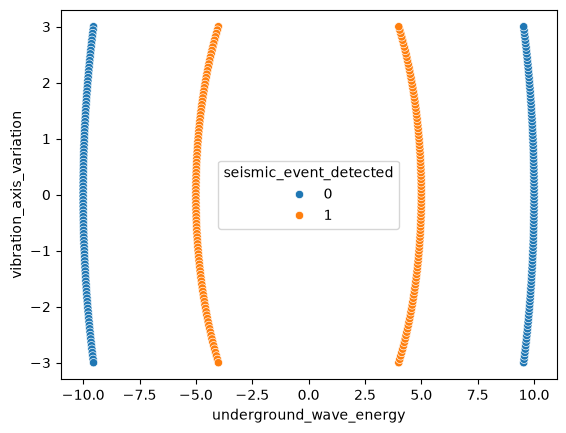

In [4]:
sns.scatterplot(x=df['underground_wave_energy'],y=df['vibration_axis_variation'],hue=df['seismic_event_detected'])
plt.show()

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [6]:
X= df.drop(['seismic_event_detected'],axis=1).values
y=df['seismic_event_detected'].values

In [7]:
type(X)

numpy.ndarray

In [8]:
y.shape

(400,)

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [11]:
X_train = torch.tensor(X_train,dtype=torch.float32)
X_test = torch.tensor(X_test,dtype=torch.float32)
y_train = torch.tensor(y_train,dtype=torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test,dtype=torch.float32).unsqueeze(1)

In [12]:
from torch import nn
class ClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1=nn.Linear(in_features=2,out_features=5)
        self.relu=nn.ReLU()
        self.layer2=nn.Linear(in_features=5,out_features=1)
    def forward(self,x):
        return self.layer2(self.relu(self.layer1(x)))

In [13]:
model=ClassificationModel()

In [14]:
loss_fn = nn.BCEWithLogitsLoss()

In [15]:
optimizer= torch.optim.Adam(params=model.parameters(),lr=0.001)

In [16]:
def calculate_accuracy(y_test,y_pred):
    correct = torch.eq(y_test,y_pred).sum().item()
    accuracy=(correct/len(y_pred))*100
    return accuracy

In [17]:
epochs=120
for epoch in range(epochs):
    model.train()
    y_logits=model(X_train)
    y_pred= torch.round(torch.sigmoid(y_logits))
    loss = loss_fn(y_logits,y_train)
    acc=calculate_accuracy(y_test=y_train,y_pred=y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.inference_mode():
        test_logits=model(X_test)
        test_pred=torch.round(torch.sigmoid(test_logits))
        test_loss=loss_fn(test_logits,y_test)
        test_acc=calculate_accuracy(y_test=y_test,y_pred=test_pred)
    if epoch %5==0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
       

Epoch: 0 | Loss: 0.63915, Accuracy: 69.38% | Test loss: 0.61360, Test acc: 72.50%
Epoch: 5 | Loss: 0.63375, Accuracy: 72.19% | Test loss: 0.60863, Test acc: 73.75%
Epoch: 10 | Loss: 0.62850, Accuracy: 73.12% | Test loss: 0.60393, Test acc: 76.25%
Epoch: 15 | Loss: 0.62340, Accuracy: 74.38% | Test loss: 0.59959, Test acc: 76.25%
Epoch: 20 | Loss: 0.61857, Accuracy: 75.62% | Test loss: 0.59576, Test acc: 77.50%
Epoch: 25 | Loss: 0.61399, Accuracy: 76.56% | Test loss: 0.59222, Test acc: 78.75%
Epoch: 30 | Loss: 0.60959, Accuracy: 77.50% | Test loss: 0.58894, Test acc: 78.75%
Epoch: 35 | Loss: 0.60530, Accuracy: 78.75% | Test loss: 0.58585, Test acc: 77.50%
Epoch: 40 | Loss: 0.60108, Accuracy: 79.06% | Test loss: 0.58295, Test acc: 78.75%
Epoch: 45 | Loss: 0.59695, Accuracy: 79.06% | Test loss: 0.58013, Test acc: 80.00%
Epoch: 50 | Loss: 0.59291, Accuracy: 78.75% | Test loss: 0.57743, Test acc: 81.25%
Epoch: 55 | Loss: 0.58899, Accuracy: 79.06% | Test loss: 0.57480, Test acc: 81.25%
Epoch: